# 00 - Data Audit and Preprocessing

**Purpose.** Discover and validate the RSNA data, parse the six labels, scan DICOM headers (restartable), check integrity, build the single patient-level split manifest used by every model, and validate preprocessing visually.

**Requires (inputs).** RSNA competition data attached (`stage_2_train/`, `stage_2_test/`, `stage_2_train.csv`, `stage_2_sample_submission.csv`); project code dataset.

**Produces (outputs, under `/kaggle/working/rsna_ich_artifacts/<MODE>/`).** `data/labels.parquet`, `data/label_report.json`, `data/metadata.parquet`, `data/metadata_integrity.json`, `data/split_manifest.csv|json`, `data/data_audit_report.json`, figures in `data/figures/`. Header cache in `shared/header_cache/`.

> Research software. Outputs are model predictions for a research study and **not** clinical diagnoses.
> Results in this notebook are only valid for the MODE they were produced in (`smoke` results check correctness and say nothing about performance).

In [1]:
# ==== Setup: locate the project code and make `src` importable ====================================
# Works on Kaggle (project code attached as a Dataset, possibly nested after zip extraction) and locally.
import os, sys, importlib
from pathlib import Path

def find_project_root(max_depth: int = 5) -> Path:
    def ok(p: Path) -> bool:
        return (p / "src" / "__init__.py").is_file() and (p / "configs" / "data_config.yaml").is_file()
    cands = []
    if os.environ.get("RSNA_ICH_PROJECT_ROOT"):
        cands.append(Path(os.environ["RSNA_ICH_PROJECT_ROOT"]))
    cands += [Path.cwd(), Path.cwd().parent, Path("/kaggle/working/RSNA_ICH_Research")]
    for c in cands:
        if ok(c):
            return c.resolve()
    for base in (Path("/kaggle/input"), Path("/kaggle/working")):
        if not base.exists():
            continue
        stack = [(base, 0)]
        while stack:
            d, depth = stack.pop()
            if ok(d):
                return d.resolve()
            if depth < max_depth:
                try:
                    stack += [(p, depth + 1) for p in d.iterdir() if p.is_dir() and not p.name.startswith("stage_2_")]
                except OSError:
                    pass
    raise FileNotFoundError(
        "Project code not found. On Kaggle: 'Add Input' -> the dataset containing RSNA_ICH_Research "
        "(with src/ and configs/). Locally: run the notebook from RSNA_ICH_Research/notebooks or set "
        "the RSNA_ICH_PROJECT_ROOT environment variable.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in ["src", "src.utils.context", "src.data", "src.models", "src.quantum", "src.training", "src.evaluation"]:
    importlib.import_module(_m)  # fails loudly here if a dependency is missing
import src
print(f"Project root: {PROJECT_ROOT}  |  src version {src.__version__}")

Project root: /kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research  |  src version 1.0.0


In [2]:
# ==== Optional dependencies ======================================================================
# Kaggle images ship torch, timm, pydicom, scikit-learn and OpenCV. PennyLane is only needed for the
# reference quantum backend (the default torch simulator does not need it). With internet enabled:
#   !pip install -q pennylane
# Without internet, attach a dataset of wheels and run: !pip install --no-index --find-links /kaggle/input/<wheels> pennylane
from src.utils.runtime import package_versions
print(package_versions())

{'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


In [3]:
# ==== Configuration ================================================================================
# MODE: "smoke" (correctness check, minutes) | "pilot" (representative subset) | "full" (largest feasible).
MODE = "pilot"
# Optional per-config overrides without editing YAML, e.g. {"transformer": {"train": {"epochs": 2}}}
OVERRIDES = {}
import json
if os.environ.get("RSNA_ICH_OVERRIDES_JSON"):          # test hook used by tools/run_notebooks_synthetic.py
    OVERRIDES = json.loads(os.environ["RSNA_ICH_OVERRIDES_JSON"])
MODE = os.environ.get("RSNA_ICH_MODE", MODE)

from src.utils.context import ProjectContext
ctx = ProjectContext(PROJECT_ROOT, MODE, OVERRIDES)
print(ctx.describe())
print("Installed packages:", ctx.runtime.packages)
ctx.save_run_info("00_data_audit")

ProjectContext(mode=pilot, root=/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research, output=/kaggle/working/rsna_ich_artifacts/pilot)
  GPU: Tesla T4 (15.6 GB), Tesla T4 (15.6 GB) | CUDA=True bf16=False | CPUs=4 | RAM avail=31.76 GB | free disk (/kaggle/working/rsna_ich_artifacts)=20.94 GB
Installed packages: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/run_info/00_data_audit.json')

In [4]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src import LABELS
from src.utils.io import atomic_write_json, atomic_save_dataframe, read_json, dataframe_to_markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## 1. Dataset discovery and component verification

In [5]:
paths = ctx.rsna  # raises a clear error if the competition data is not attached
print(json.dumps(paths.as_dict(), indent=2))
if paths.missing:
    print("WARNING - missing components:", paths.missing)
dcfg = ctx.cfg["data"]
data_dir = ctx.dir("data"); fig_dir = ctx.dir("data", "figures")
print("Raw CSV schema (first rows):")
display(pd.read_csv(paths.train_csv, nrows=12))
if paths.sample_submission.exists():
    display(pd.read_csv(paths.sample_submission, nrows=7))

{
  "root": "/kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection",
  "train_dir": "/kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_train",
  "test_dir": "/kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_test",
  "train_csv": "/kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_train.csv",
  "sample_submission": "/kaggle/input/competitions/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection/stage_2_sample_submission.csv",
  "missing": []
}
Raw CSV schema (first rows):


,ID,Label
0,ID_12cadc6af_epidural,0
1,ID_12cadc6af_intraparenchymal,0
2,ID_12cadc6af_intraventricular,0
3,ID_12cadc6af_subarachnoid,0
4,ID_12cadc6af_subdural,0
5,ID_12cadc6af_any,0
6,ID_38fd7baa0_epidural,0
7,ID_38fd7baa0_intraparenchymal,0
8,ID_38fd7baa0_intraventricular,0
9,ID_38fd7baa0_subarachnoid,0


,ID,Label
0,ID_0fbf6a978_epidural,0.5
1,ID_0fbf6a978_intraparenchymal,0.5
2,ID_0fbf6a978_intraventricular,0.5
3,ID_0fbf6a978_subarachnoid,0.5
4,ID_0fbf6a978_subdural,0.5
5,ID_0fbf6a978_any,0.5
6,ID_d62ec3412_epidural,0.5


## 2. Labels: parse, validate and pivot to one six-label vector per image
The CSV is long format (`ID_<image>_<label>`, one row per label). Duplicates, malformed IDs, fractional values and `any` consistency are reported, not silently fixed.

In [6]:
from src.data.csv_parser import parse_label_csv, label_distribution_table
lab_path, rep_path = data_dir / "labels.parquet", data_dir / "label_report.json"
policy = dcfg["labels"]["conflict_policy"]
if lab_path.exists() and rep_path.exists() and read_json(rep_path).get("conflict_policy") == policy:
    labels, label_report = pd.read_parquet(lab_path), read_json(rep_path)
    print("Loaded cached labels.")
else:
    labels, rep = parse_label_csv(paths.train_csv, conflict_policy=policy)
    label_report = rep.as_dict()
    atomic_save_dataframe(labels, lab_path); atomic_write_json(rep_path, label_report)
for k in ["n_rows_raw", "n_rows_malformed", "n_exact_duplicate_rows", "n_conflicting_duplicate_pairs", "n_images",
          "n_images_missing_labels", "has_fractional_values", "unique_values",
          "n_any_inconsistent_subtype_without_any", "n_any_inconsistent_any_without_subtype"]:
    print(f"{k:45s} {label_report[k]}")
if label_report["conflicting_examples"]:
    print("Conflicting duplicates (resolved with policy =", policy, "):", label_report["conflicting_examples"][:5])
display(label_distribution_table(labels))
print("Number of subtypes per ICH-positive image:", label_report["n_labels_per_positive_image"])

n_rows_raw                                    4516842
n_rows_malformed                              0
n_exact_duplicate_rows                        24
n_conflicting_duplicate_pairs                 0
n_images                                      752803
n_images_missing_labels                       0
has_fractional_values                         False
unique_values                                 [0.0, 1.0]
n_any_inconsistent_subtype_without_any        0
n_any_inconsistent_any_without_subtype        0


,n_images,positives,prevalence
epidural,752803,3145,0.004178
intraparenchymal,752803,36118,0.047978
intraventricular,752803,26205,0.034810
subarachnoid,752803,35675,0.047390
subdural,752803,47166,0.062654
any,752803,107933,0.143375


Number of subtypes per ICH-positive image: {'1': 75859, '2': 24826, '3': 6217, '4': 1008, '5': 23}


## 3. Files on disk vs. labelled IDs

In [7]:
listing_path = data_dir / "train_dir_listing.parquet"
if listing_path.exists():
    files = pd.read_parquet(listing_path)
else:
    files = pd.DataFrame({"image_id": [e.name[:-4] for e in os.scandir(paths.train_dir) if e.name.endswith(".dcm")]})
    atomic_save_dataframe(files, listing_path)
ids_csv, ids_dir = set(labels["image_id"]), set(files["image_id"])
labelled_without_dicom = sorted(ids_csv - ids_dir)
dicom_without_label = sorted(ids_dir - ids_csv)
print(f"DICOM files in stage_2_train: {len(ids_dir):,} | labelled images: {len(ids_csv):,}")
print(f"labelled but no DICOM file: {len(labelled_without_dicom):,} {labelled_without_dicom[:5]}")
print(f"DICOM file but no label:    {len(dicom_without_label):,} {dicom_without_label[:5]}")

DICOM files in stage_2_train: 752,803 | labelled images: 752,803
labelled but no DICOM file: 0 []
DICOM file but no label:    0 []


## 4. DICOM header scan (restartable, cached)
Only headers are read. Chunks are saved as they complete, so an interrupted session resumes. In `smoke` mode a random subset is scanned: this is leakage-safe (unscanned images are simply never used), but studies are incomplete.

In [8]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"Invalid value for VR UI:.*",
    category=UserWarning,
    module=r"pydicom\.valuerep"
)
from src.data.dicom_metadata import scan_headers, metadata_integrity_report, add_slice_order
hs = dcfg["header_scan"]
ctx.restore_shared_cache()  # reuse a previous version's scan if its output is attached
scan_ids = labels.loc[labels["image_id"].isin(ids_dir), "image_id"]
if hs["max_images"]:
    scan_ids = scan_ids.sample(n=min(int(hs["max_images"]), len(scan_ids)), random_state=dcfg["seed"])
meta = scan_headers(scan_ids, paths.train_dir, ctx.shared_dir("header_cache"), hs["chunk_size"], hs["workers"])
integrity = metadata_integrity_report(meta, len(scan_ids))
integrity["labelled_without_dicom"] = len(labelled_without_dicom)
integrity["dicom_without_label"] = len(dicom_without_label)
n_available = int(labels["image_id"].isin(ids_dir).sum())
integrity["partial_scan"] = bool(hs["max_images"]) and int(hs["max_images"]) < n_available
atomic_write_json(data_dir / "metadata_integrity.json", integrity)
meta_ok = add_slice_order(meta[meta["read_ok"].astype(bool)])
atomic_save_dataframe(meta_ok, data_dir / "metadata.parquet")
print(json.dumps({k: v for k, v in integrity.items() if k != "unreadable_examples"}, indent=1, default=str))
if integrity["partial_scan"]:
    print("NOTE: partial header scan (smoke). Studies are incomplete; study-level results are not meaningful in this mode.")

[header scan] requested=752,803 cached=0 to_read=752,803
  scanned 5,000/752,803  (165 files/s, ETA 75.4 min)
  scanned 10,000/752,803  (93 files/s, ETA 133.4 min)
  scanned 15,000/752,803  (80 files/s, ETA 154.3 min)
  scanned 20,000/752,803  (75 files/s, ETA 162.8 min)
  scanned 25,000/752,803  (72 files/s, ETA 169.1 min)
  scanned 30,000/752,803  (69 files/s, ETA 174.4 min)
  scanned 35,000/752,803  (68 files/s, ETA 175.6 min)
  scanned 40,000/752,803  (67 files/s, ETA 176.1 min)
  scanned 45,000/752,803  (67 files/s, ETA 176.1 min)
  scanned 50,000/752,803  (67 files/s, ETA 175.5 min)
  scanned 55,000/752,803  (66 files/s, ETA 175.7 min)
  scanned 60,000/752,803  (66 files/s, ETA 175.1 min)
  scanned 65,000/752,803  (66 files/s, ETA 174.0 min)
  scanned 70,000/752,803  (66 files/s, ETA 173.4 min)
  scanned 75,000/752,803  (65 files/s, ETA 173.4 min)
  scanned 80,000/752,803  (65 files/s, ETA 173.1 min)
  scanned 85,000/752,803  (65 files/s, ETA 171.9 min)
  scanned 90,000/752,803  

## 5. Patient-level split manifest (created once, reused by every model)
All images of a patient go to one split. Stratification is at patient level (epidural / other ICH / negative). If an existing manifest was built with a different configuration the notebook stops instead of overwriting it.

In [9]:
from src.data.splitting import make_patient_split, save_manifest, load_manifest, overlap_report
from src.utils.config import config_fingerprint
FORCE_NEW_MANIFEST = False
sp = dcfg["split"]
split_fp = config_fingerprint({"split": sp, "seed": dcfg["seed"], "header_scan": hs, "labels": dcfg["labels"]})
man_csv = data_dir / "split_manifest.csv"
if man_csv.exists() and not FORCE_NEW_MANIFEST:
    manifest, man_info = load_manifest(man_csv)
    if man_info.get("split_config_fingerprint") != split_fp:
        raise RuntimeError("An existing split manifest was built with a different configuration. Every trained model "
                           "depends on it. Set FORCE_NEW_MANIFEST=True only if you intend to invalidate those results.")
    print("Reusing existing manifest", man_info["manifest_hash"][:12])
else:
    if man_csv.exists():
        old = read_json(man_csv.with_suffix(".json"))
        arch = ctx.dir("data", "archive", old["manifest_hash"][:12])
        man_csv.replace(arch / man_csv.name); man_csv.with_suffix(".json").replace(arch / "split_manifest.json")
        print("Archived previous manifest to", arch)
    df = labels.merge(meta_ok, on="image_id", how="inner")
    manifest, man_info = make_patient_split(df, sp["fractions"], dcfg["seed"], sp["max_groups"],
                                            sp["max_missing_patient_fraction"], sp["min_positive_group_fraction"])
    man_info.update(split_config_fingerprint=split_fp, mode=MODE, partial_header_scan=integrity["partial_scan"],
                    label_report_conflict_policy=policy)
    save_manifest(manifest, man_info, data_dir)
    manifest, man_info = load_manifest(man_csv)
print("Grouping level:", man_info["grouping_level"], "| manifest hash:", man_info["manifest_hash"][:16])
if man_info["grouping_level"] != "patient":
    print("WARNING: PatientID missing for too many images -> STUDY-level fallback split. Do not call it patient-level.")
summary = pd.DataFrame({s: {"images": v["n_images"], "patients/groups": v["n_groups"], "studies": v["n_studies"],
                            **{f"pos_{l}": v["positives"][l] for l in LABELS}} for s, v in man_info["splits"].items()}).T
display(summary)
print("Overlap report (must be all zeros):", overlap_report(manifest))

Grouping level: patient | manifest hash: 749222703ee2526a


,images,patients/groups,studies,pos_epidural,pos_intraparenchymal,pos_intraventricular,pos_subarachnoid,pos_subdural,pos_any
train,42889,1051,1237,163,1976,1515,2237,2647,6175
val,8618,225,249,30,394,335,560,660,1401
test,9552,225,277,37,459,380,628,611,1472


Overlap report (must be all zeros): {'group_id': {'train&val': 0, 'train&test': 0, 'val&test': 0}, 'patient_id': {'train&val': 0, 'train&test': 0, 'val&test': 0}, 'study_uid': {'train&val': 0, 'train&test': 0, 'val&test': 0}, 'image_id': {'train&val': 0, 'train&test': 0, 'val&test': 0}, 'duplicate_image_ids': 0}


## 6. Label distribution by partition

split,test,train,val
label,,,
epidural,0.003874,0.003801,0.003481
intraparenchymal,0.048053,0.046072,0.045718
intraventricular,0.039782,0.035324,0.038872
subarachnoid,0.065745,0.052158,0.064980
subdural,0.063966,0.061717,0.076584
any,0.154104,0.143976,0.162567


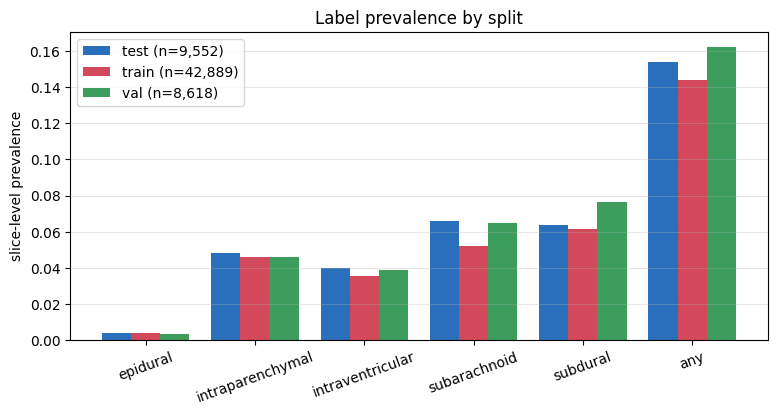

In [10]:
from src.evaluation.visualization import plot_label_distribution
dist = label_distribution_table(manifest, by="split")
display(dist.pivot(index="label", columns="split", values="prevalence").loc[list(LABELS)])
plot_label_distribution(dist, fig_dir / "label_distribution_by_split.png"); plt.show()

## 7. Preprocessing validation (visual)
HU conversion (with the RSNA 12-bit intercept fix), brain / subdural / soft-tissue windows, resize. The same function is used for training and inference (fingerprinted).

Preprocessing: PreprocessConfig(image_size=224, channel_mode='bsb', windows=None, rsna_intercept_fix=True, pad_to_square=True, normalization='imagenet', interpolation='area', extra={}) | fingerprint 1b20cefd4c2364fd


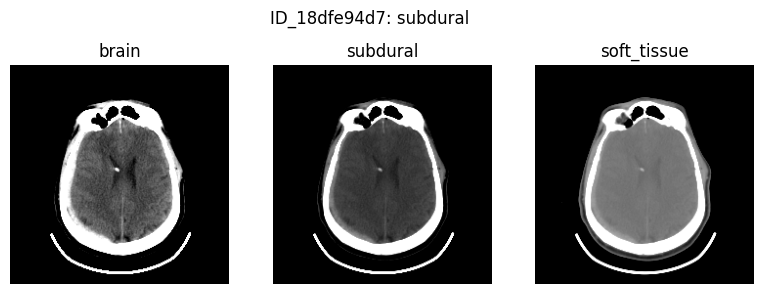

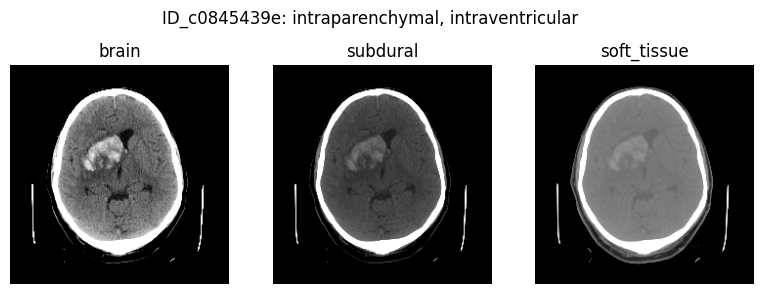

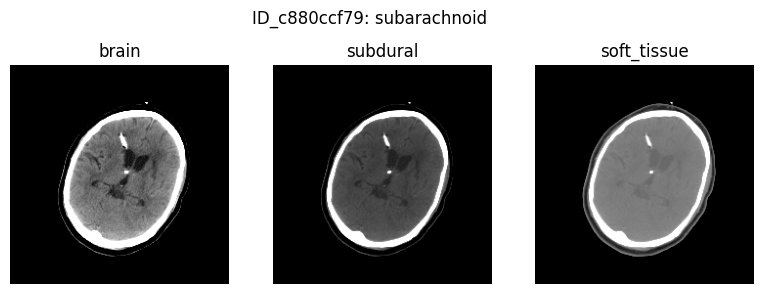

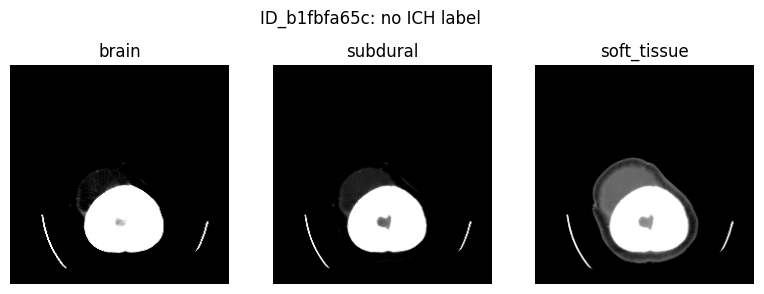

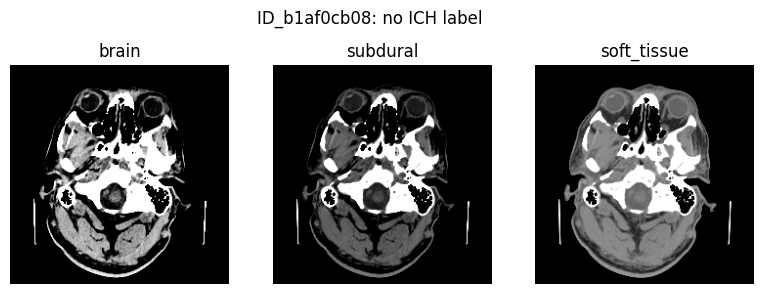

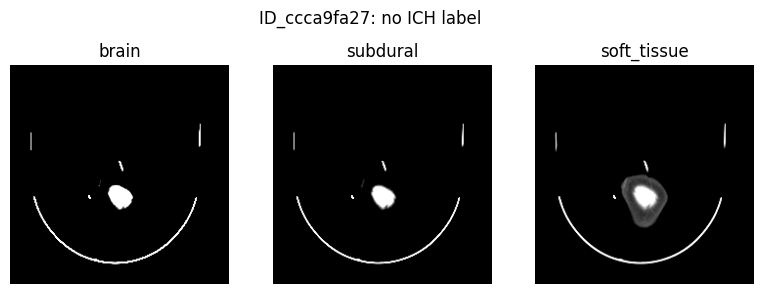

Single-window ablation input uses channels: ('brain', 'brain', 'brain')


In [11]:
from src.data.preprocessing import PreprocessConfig, load_dicom_channels, preprocessing_fingerprint, CHANNEL_MODES
from src.evaluation.visualization import plot_windows
pp = PreprocessConfig.from_dict(dcfg["preprocessing"])
print("Preprocessing:", pp, "| fingerprint", preprocessing_fingerprint(pp))
rng = np.random.default_rng(0)
pos = manifest[manifest["any"] >= 0.5]["image_id"].tolist(); neg = manifest[manifest["any"] < 0.5]["image_id"].tolist()
show = list(rng.choice(pos, min(3, len(pos)), replace=False)) + list(rng.choice(neg, min(3, len(neg)), replace=False))
for iid in show[: dcfg["visual_check_images"]]:
    ch = load_dicom_channels(str(paths.train_dir / f"{iid}.dcm"), pp)
    row = manifest.set_index("image_id").loc[iid]
    title = f"{iid}: " + (", ".join(l for l in LABELS[:-1] if row[l] >= 0.5) or "no ICH label")
    plot_windows(ch, pp.window_names, title, fig_dir / f"windows_{iid}.png"); plt.show()
single = PreprocessConfig.from_dict({**dcfg["preprocessing"], "channel_mode": "brain3"})
print("Single-window ablation input uses channels:", single.window_names)

## 8. Competition test folder (inference only)
`stage_2_test` has no labels. It is never part of the research manifest.

In [12]:
from src.data.csv_parser import parse_submission_ids
if paths.sample_submission.exists() and paths.test_dir.exists():
    test_ids = parse_submission_ids(paths.sample_submission)
    test_files = {e.name[:-4] for e in os.scandir(paths.test_dir) if e.name.endswith(".dcm")}
    print(f"competition test images in sample submission: {len(test_ids):,}; DICOMs on disk: {len(test_files):,}; "
          f"missing files: {len(set(test_ids.image_id) - test_files):,}")
    assert not (set(test_ids.image_id) & set(manifest.image_id)), "competition test IDs must not appear in the manifest"

competition test images in sample submission: 121,232; DICOMs on disk: 121,232; missing files: 0


## 9. Save the data-audit report

In [13]:
report = {"mode": MODE, "paths": paths.as_dict(), "label_report": label_report, "integrity": integrity,
          "manifest": {k: v for k, v in man_info.items() if k != "overlap"}, "overlap": overlap_report(manifest),
          "preprocessing": {"config": dcfg["preprocessing"], "fingerprint": preprocessing_fingerprint(pp)}}
atomic_write_json(data_dir / "data_audit_report.json", report)
print("Saved:", sorted(p.name for p in data_dir.iterdir()))

Saved: ['data_audit_report.json', 'figures', 'label_report.json', 'labels.parquet', 'metadata.parquet', 'metadata_integrity.json', 'split_manifest.csv', 'split_manifest.json', 'train_dir_listing.parquet']


**Next:** Save this notebook version (Kaggle: *Save Version → Save & Run All*) so `/kaggle/working` becomes a persistent output, then attach it as input to notebooks 01-05.